In [12]:
# Per leggere i file
import gzip
import pickle
import math

import numpy as np
from sktime.clustering.k_means import TimeSeriesKMeans
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import pandas as pd
from tqdm.notebook import tqdm


# Dim reduction
import pacmap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# per feature importance
from sklearn.ensemble import RandomForestClassifier

## Caricamento Dati
---

In [13]:
with gzip.open("ts_datasetwise_transformed_paa.pkl.gz", "rb") as f:
    ts = pickle.load(f)


# id non serve per il clustering, anzi può essere dannoso
for df in ts:
    if 'id' in df.columns:
        df.drop(columns=['id'], inplace=True)  # inutile
    if 'non-wear_flag' in df.columns:
        # inutile perchè quasi tutta = 0
        df.drop(columns=['non-wear_flag'], inplace=True)
    if 'battery_voltage' in df.columns:
        # inutile perchè quasi tutta = 0
        df.drop(columns=['battery_voltage'], inplace=True)
'''    if 'X' in df.columns:
        df.drop(columns=['X'], inplace=True)  # per multicollinearità
    if 'Y' in df.columns:
        df.drop(columns=['Y'], inplace=True)  # per multicollinearità
    if 'Z' in df.columns:
        df.drop(columns=['Z'], inplace=True)  # per multicollinearità'''

"    if 'X' in df.columns:\n        df.drop(columns=['X'], inplace=True)  # per multicollinearità\n    if 'Y' in df.columns:\n        df.drop(columns=['Y'], inplace=True)  # per multicollinearità\n    if 'Z' in df.columns:\n        df.drop(columns=['Z'], inplace=True)  # per multicollinearità"

In [14]:
oppa = ts[0]

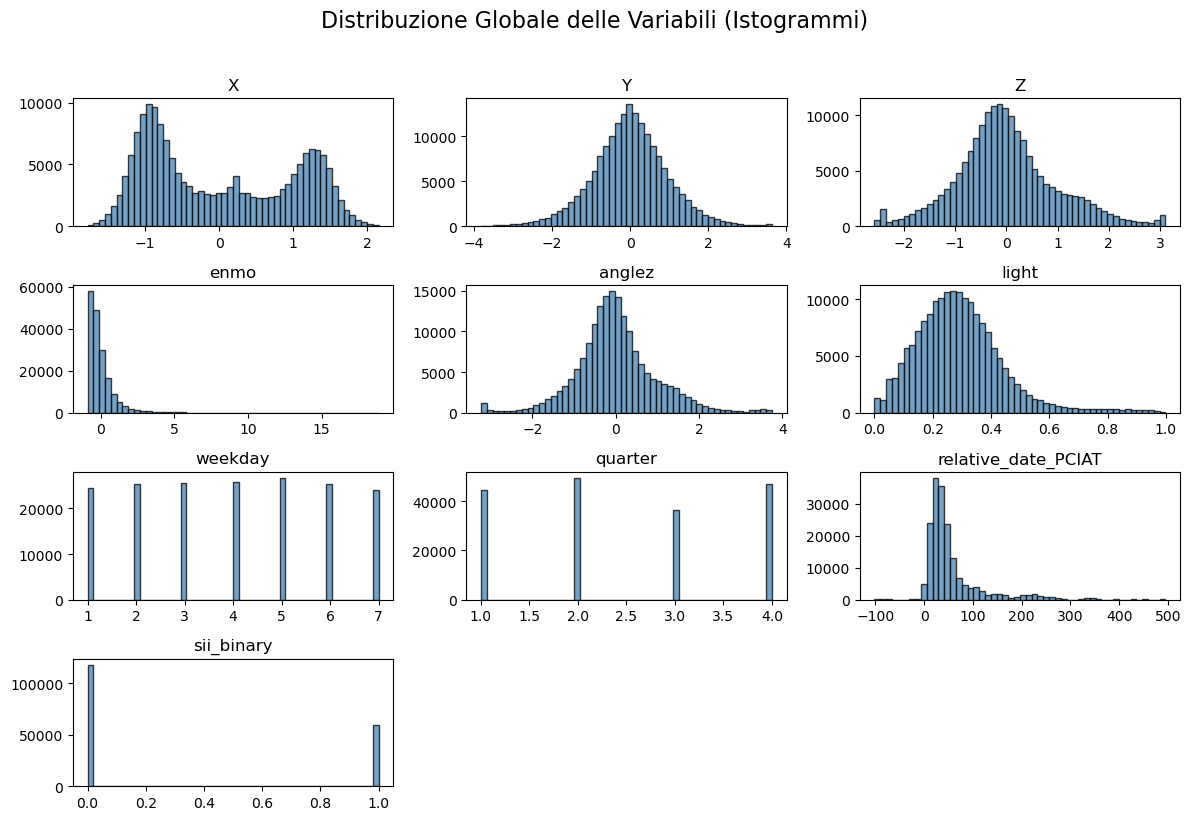

In [15]:
ts_globale = pd.concat(ts, ignore_index=True)

# Opzionale: campionamento per velocizzare la generazione grafica in caso di dataset massivi.
# Se si desidera analizzare il 100% dei dati, lasciare frac=1.0.
df_plot = ts_globale.sample(frac=1.0, random_state=222)

# ==========================================
# 3. Visualizzazione tramite Istogrammi
# ==========================================
# Viene creata una griglia automatica in base al numero di colonne
df_plot.hist(bins=50, figsize=(12, 8), edgecolor='black',
             grid=False, alpha=0.75, color='steelblue')
plt.suptitle("Distribuzione Globale delle Variabili (Istogrammi)",
             y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## Approximate Clustering
---
Ho provato a fare whole clustering, ma era computazinalmente troppo pesante

In [16]:
# Gestione dati per clustering più memoria sii

sii_labels = []
weekday_labels = []
quarter_labels = []
relative_date_labels = []

X_clustering_list = []
X_flattened_list = []

for df in ts:
    # Si estraggono i valori (costanti per l'intera serie temporale)
    sii_labels.append(df['sii_binary'].iloc[0])
    weekday_labels.append(df['weekday'].iloc[0])
    quarter_labels.append(df['quarter'].iloc[0])
    relative_date_labels.append(df['relative_date_PCIAT'].iloc[0])

    # Rimozione delle colonne prima di passare i dati agli algoritmi
    colonne_da_rimuovere = ['sii_binary',
                            'weekday', 'quarter', 'relative_date_PCIAT']
    df_clustering = df.drop(columns=colonne_da_rimuovere)

    X_clustering_list.append(df_clustering)

    # Preparazione per il clustering gerarchico
    X_flattened_list.append(df_clustering.values.flatten())

# Conversione in array NumPy
sii_labels = np.array(sii_labels)
weekday_labels = np.array(weekday_labels)
quarter_labels = np.array(quarter_labels)
relative_date_labels = np.array(relative_date_labels)

X_flattened = np.array(X_flattened_list)

# Preparazione del formato 3D per sktime (n_istanze, n_variabili, n_timepoints)
X_array = np.array(X_clustering_list)
X_sktime = np.transpose(X_array, (0, 2, 1))

In [ ]:
# Clustering

# K-Means Euclideo
kmeans_euclidean = TimeSeriesKMeans(
    n_clusters=3,
    metric="euclidean",
    init_algorithm="kmeans++",
    n_init=10,
    random_state=222
)
labels_kmeans_euclidean = kmeans_euclidean.fit_predict(X_sktime)

# K-Means DTW
kmeans_dtw = TimeSeriesKMeans(
    n_clusters=3,
    metric="dtw",
    init_algorithm="kmeans++",
    n_init=5,
    random_state=222,
    distance_params={"window": 0.1}
)
labels_kmeans_dtw = kmeans_dtw.fit_predict(X_sktime)

# Clustering Gerarchico (Agglomerativo)

k_ger = 3
hierarchical_euclidean = AgglomerativeClustering(
    n_clusters=k_ger,
    metric='euclidean',
    linkage='ward'
)
labels_ger_euclidean = hierarchical_euclidean.fit_predict(X_flattened)

'''hierarchical_dtw = AgglomerativeClustering(
    n_clusters=k_ger,
    metric='dtw',
    linkage='ward'
)
labels_ger_dtw = hierarchical_dtw.fit_predict(X_flattened)'''


print("Numerosità K-Means Euclideo:", np.bincount(labels_kmeans_euclidean))
print("Numerosità K-Means DTW:", np.bincount(labels_kmeans_dtw))
print("Numerosità Gerarchico Euclideo:", np.bincount(labels_ger_euclidean))
# print("Numerosità Gerarchico DTW:", np.bincount(labels_ger_dtw))

Numerosità K-Means Euclideo: [1344 1728  691  674]
Numerosità K-Means DTW: [ 744 1408 2285]
Numerosità Gerarchico Euclideo: [2427 1573  437]


## Visualizzazione
---

In [18]:
# Per Grafici
dict_labels = {
    "labels_kmeans_euclidean": labels_kmeans_euclidean,
    "labels_kmeans_dtw": labels_kmeans_dtw,
    "labels_ger_euclidean": labels_ger_euclidean
}

### Feature Importance


Importanza globale - labels_kmeans_euclidean:
Variable_Group  Importance
             X    0.420153
        anglez    0.243023
             Z    0.238054
          enmo    0.044350
             Y    0.030347
         light    0.024073

Importanza globale - labels_kmeans_dtw:
Variable_Group  Importance
             X    0.571283
             Z    0.201980
        anglez    0.188428
             Y    0.014668
          enmo    0.011875
         light    0.011766

Importanza globale - labels_ger_euclidean:
Variable_Group  Importance
             X    0.620946
             Z    0.148166
        anglez    0.143334
             Y    0.035772
          enmo    0.031337
         light    0.020445


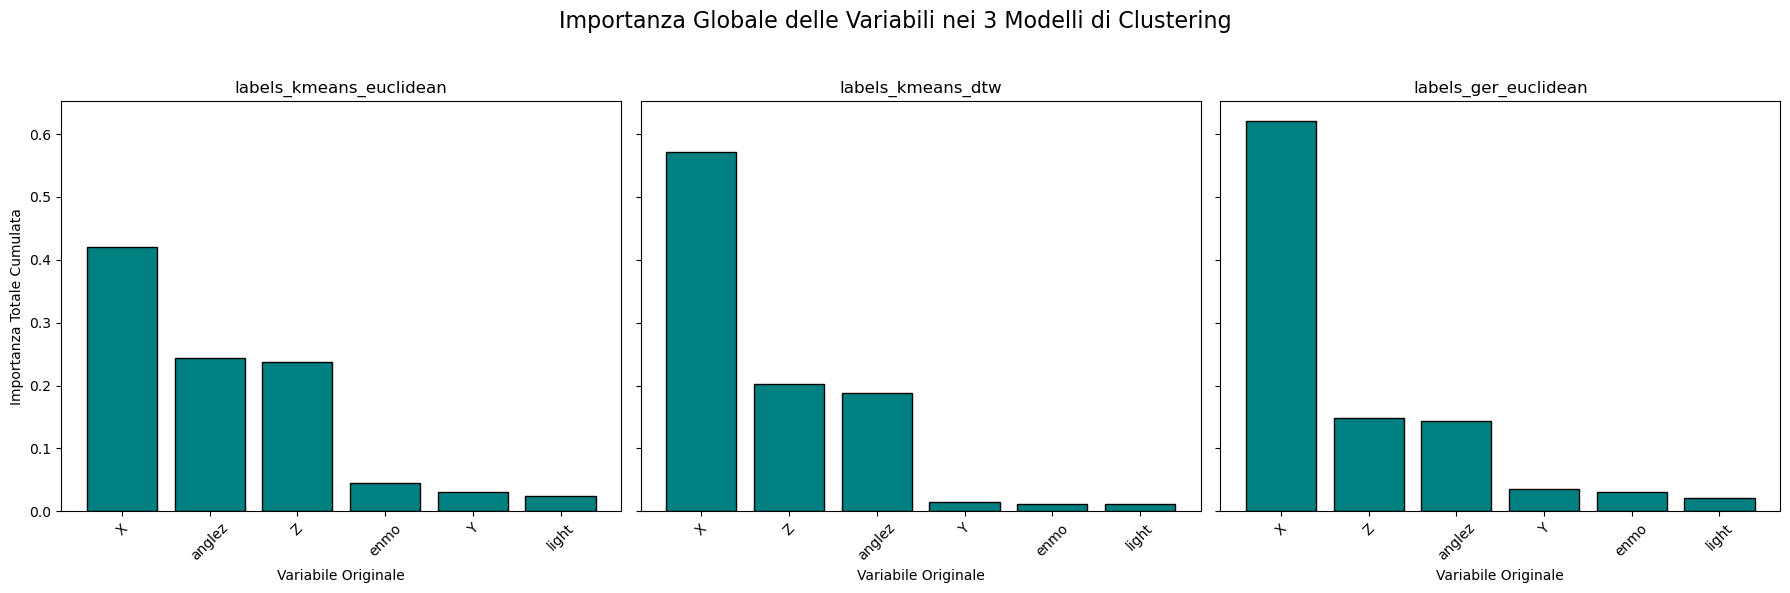

In [19]:
colonne_reali = X_clustering_list[0].columns.tolist()
n_timepoints = len(X_clustering_list[0])
feature_names = []
for t in range(n_timepoints):
    for col in colonne_reali:
        feature_names.append(f"{col}_t{t}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
fig.suptitle(
    "Importanza Globale delle Variabili nei 3 Modelli di Clustering", fontsize=16)

for ax, (nome_modello, labels) in zip(axes, dict_labels.items()):

    clf = RandomForestClassifier(random_state=222, n_estimators=100)
    clf.fit(X_flattened, labels)

    importances = clf.feature_importances_

    df_importance = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })

    df_importance['Variable_Group'] = df_importance['Feature'].apply(
        lambda x: x.split('_t')[0])
    df_group_importance = df_importance.groupby(
        'Variable_Group')['Importance'].sum().reset_index()
    df_group_importance = df_group_importance.sort_values(
        by='Importance', ascending=False)

    print(f"\nImportanza globale - {nome_modello}:")
    print(df_group_importance.to_string(index=False))

    # Visualizzazione grafica nel subplot corrispondente
    ax.bar(
        df_group_importance['Variable_Group'],
        df_group_importance['Importance'],
        color='teal',
        edgecolor='black'
    )

    # Formattazione del singolo grafico
    ax.set_title(nome_modello)
    ax.set_xlabel('Variabile Originale')
    ax.tick_params(axis='x', rotation=45)

    # Inserimento della label y solo sul primo grafico a sinistra
    if ax == axes[0]:
        ax.set_ylabel('Importanza Totale Cumulata')

# Ottimizzazione degli spazi
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 2D Visualization

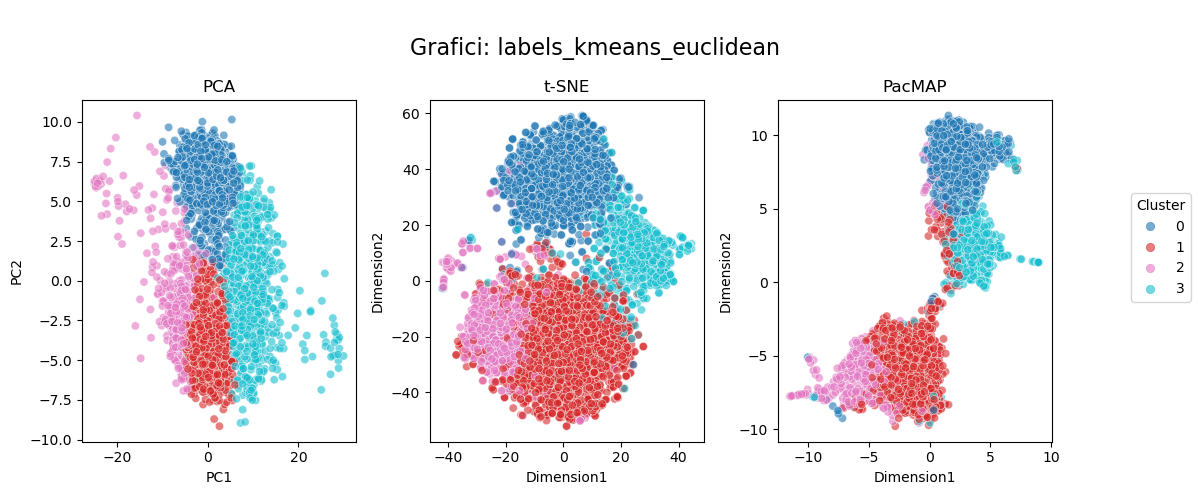

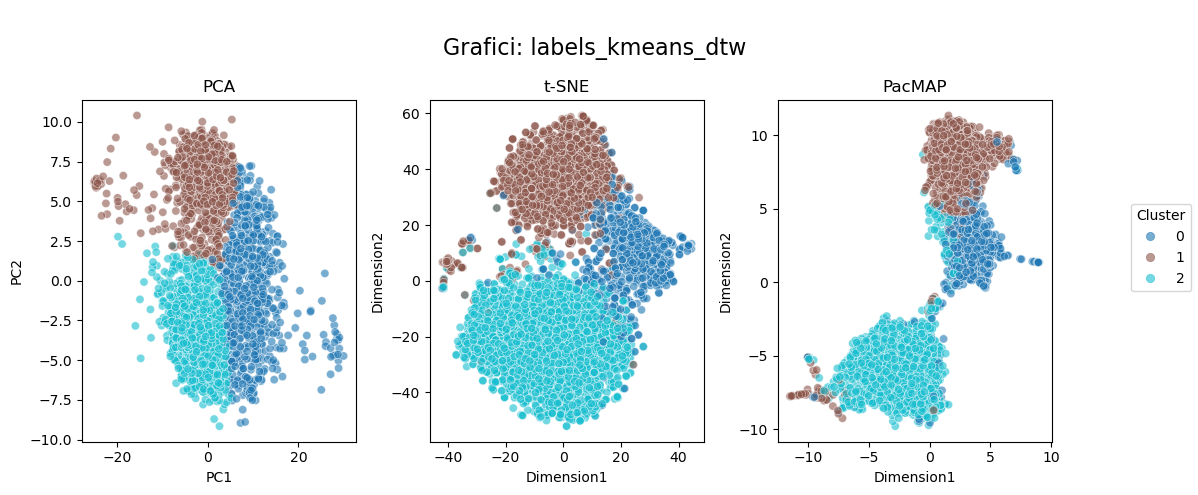

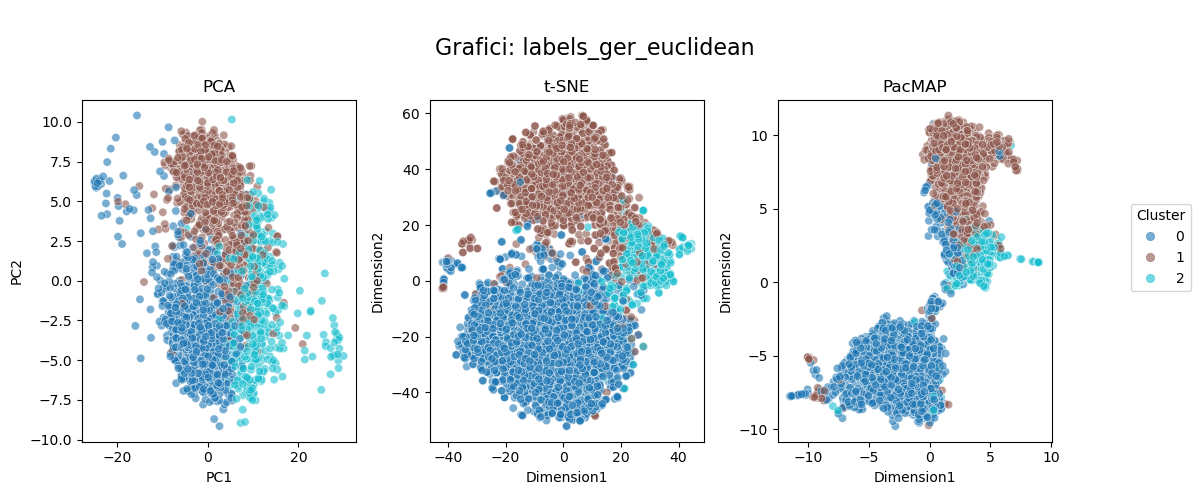

In [20]:
# Visualizzazione su dimensini ridotte

# PCA
pca = PCA(n_components=2, random_state=222)
X_pca = pca.fit_transform(X_flattened)

# t-SNE
tsne = TSNE(n_components=2, random_state=222)
X_tsne = tsne.fit_transform(X_flattened)

# PacMAP
# L'inizializzazione con PCA è raccomandata per PacMAP per migliorare la stabilità
pm = pacmap.PaCMAP(n_components=2, random_state=222)
X_pacmap = pm.fit_transform(X_flattened, init="pca")

# ==========================================
# 2. Visualizzazione
# ==========================================

for title_label, colors in dict_labels.items():
    fig, axes = plt.subplots(1, 3, figsize=(12, 5))
    fig.suptitle(
        f"\nGrafici: {title_label}", fontsize=16)

    # Grafico PCA
    scatter_pca = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=colors,
                                  cmap='tab10', alpha=0.6, edgecolors='w', linewidth=0.5)
    axes[0].set_title('PCA')
    axes[0].set_xlabel('PC1')
    axes[0].set_ylabel('PC2')

    # Grafico t-SNE
    scatter_tsne = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=colors,
                                   cmap='tab10', alpha=0.6, edgecolors='w', linewidth=0.5)
    axes[1].set_title('t-SNE')
    axes[1].set_xlabel('Dimension1')
    axes[1].set_ylabel('Dimension2')

    # Grafico PacMAP
    scatter_pacmap = axes[2].scatter(X_pacmap[:, 0], X_pacmap[:, 1],
                                     c=colors, cmap='tab10', alpha=0.6, edgecolors='w', linewidth=0.5)
    axes[2].set_title('PacMAP')
    axes[2].set_xlabel('Dimension1')
    axes[2].set_ylabel('Dimension2')

    # Aggiunta di una legenda per i cluster
    # Utilizza le informazioni dell'ultimo scatter plot per generare la legenda
    legend = fig.legend(*scatter_pacmap.legend_elements(),
                        title="Cluster", loc='center right')
    fig.subplots_adjust(right=0.92)  # Spazio per la legenda

    plt.tight_layout(rect=[0, 0, 0.9, 1])
    plt.show()

### Visualizzazione Centroidi

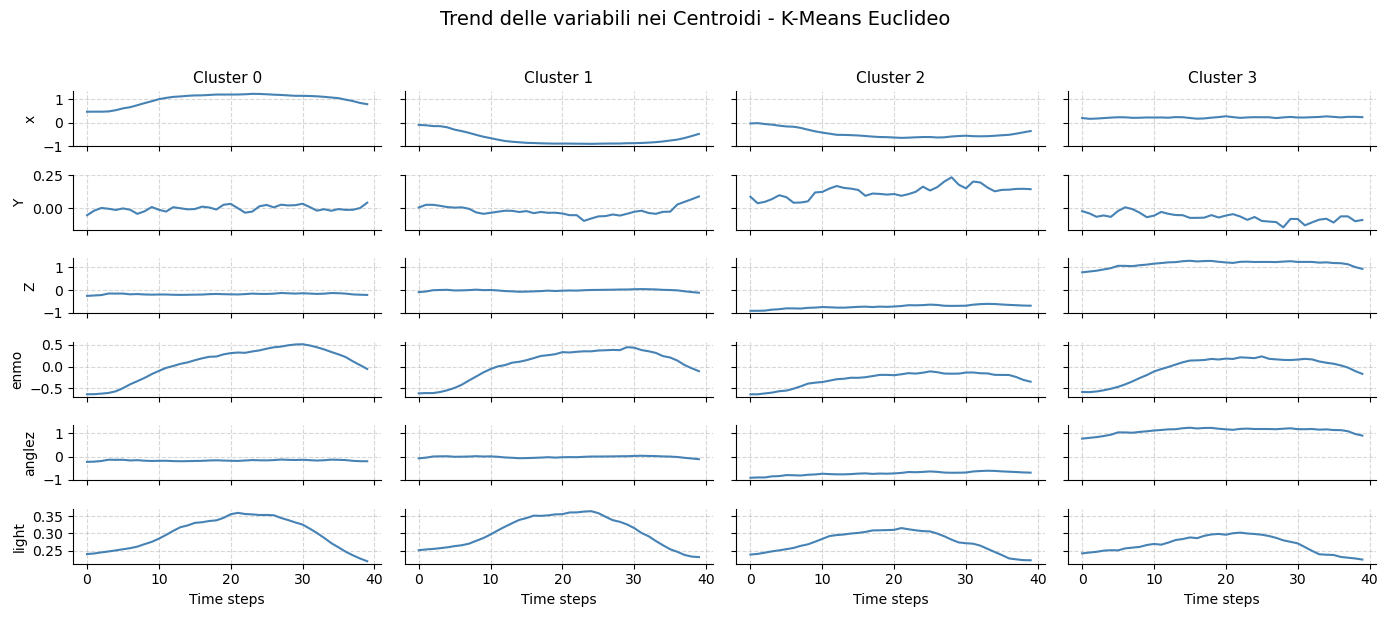

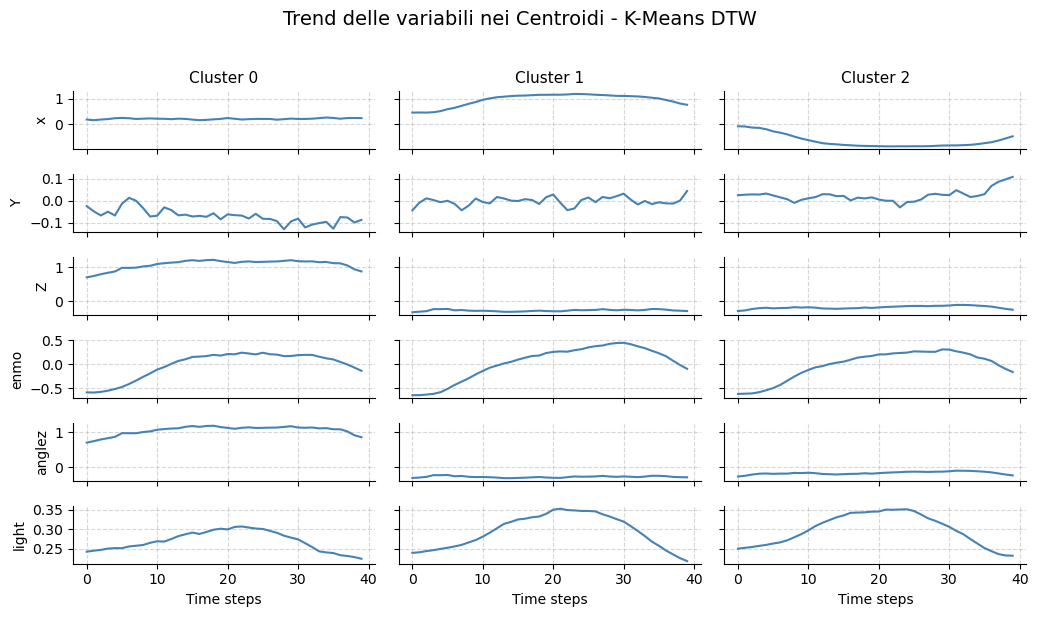

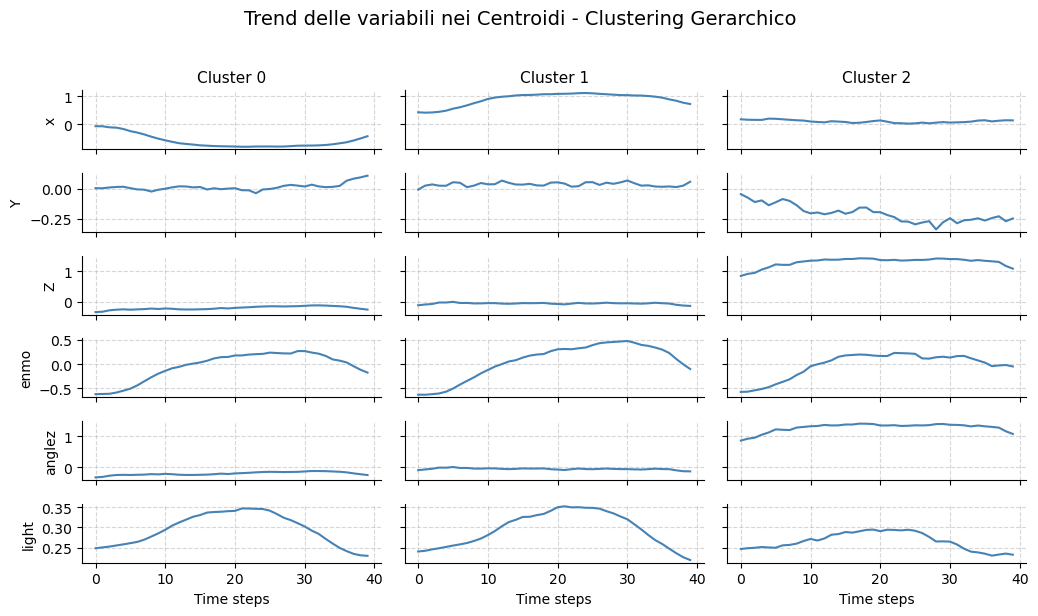

In [21]:
# Valutazione centroidi

centroidi_euclidean = kmeans_euclidean.cluster_centers_
centroidi_dtw = kmeans_dtw.cluster_centers_

centroidi_ger_list = []

for cluster_id in range(k_ger):
    serie_nel_cluster = X_sktime[labels_ger_euclidean == cluster_id]

    centroide = np.mean(serie_nel_cluster, axis=0)
    centroidi_ger_list.append(centroide)

centroidi_ger = np.array(centroidi_ger_list)


dict_centroids = {
    "K-Means Euclideo": centroidi_euclidean,
    "K-Means DTW": centroidi_dtw,
    "Clustering Gerarchico": centroidi_ger
}

nomi_colonne = [
    "x", "Y", "Z", "enmo", "anglez", "light"
]


ict_centroids = {
    "K-Means Euclideo": centroidi_euclidean,
    "K-Means DTW": centroidi_dtw,
    "Clustering Gerarchico": centroidi_ger
}

for nome_tecnica, centroidi in dict_centroids.items():
    num_clusters = len(centroidi)
    num_vars = len(nomi_colonne)

    # Creazione della griglia: righe = variabili, colonne = cluster
    # sharey='row' garantisce che la scala di una variabile sia identica tra i cluster
    fig, axes = plt.subplots(
        nrows=num_vars,
        ncols=num_clusters,
        # Larghezza dinamica in base al numero di cluster
        figsize=(3.5 * num_clusters, 6),
        sharex=True,
        sharey='row'
    )

    fig.suptitle(
        f"Trend delle variabili nei Centroidi - {nome_tecnica}", fontsize=14, y=1.02)

    for i, centroide in enumerate(centroidi):
        centroide_trasposto = centroide.T

        for j, col_name in enumerate(nomi_colonne):
            # Selezione dell'asse corretto (gestisce anche il caso limite di 1 solo cluster)
            ax = axes[j, i] if num_clusters > 1 else axes[j]

            # Tracciamento della linea
            ax.plot(centroide_trasposto[:, j],
                    color='steelblue', linewidth=1.5)

            # Formattazione: Titoli solo sulla prima riga in alto
            if j == 0:
                ax.set_title(f"Cluster {i}", fontsize=11)

            # Formattazione: Etichette Y (nomi variabili) solo sulla prima colonna a sinistra
            if i == 0:
                ax.set_ylabel(col_name, fontsize=10)

            # Pulizia visiva rimuovendo i bordi superflui
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle='--', alpha=0.5)

    # Impostazione dell'etichetta X ("Time steps") solo sull'ultima riga in basso
    for i in range(num_clusters):
        ax_bottom = axes[-1, i] if num_clusters > 1 else axes[-1]
        ax_bottom.set_xlabel("Time steps", fontsize=10)

    plt.tight_layout()
    plt.show()

### Istogrammi dei Clusters

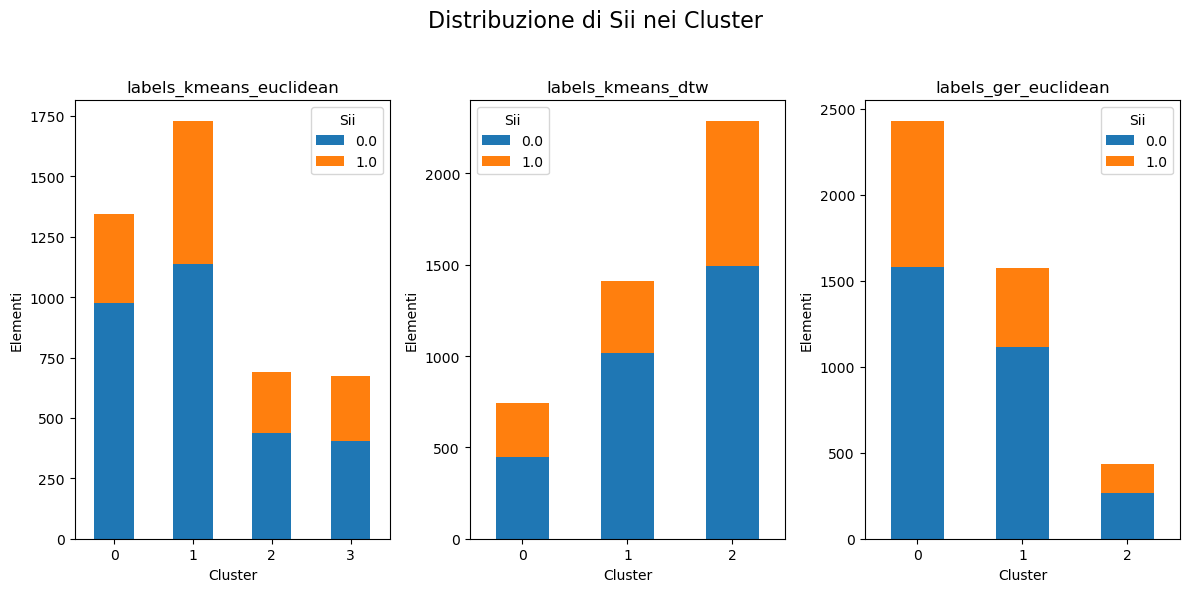

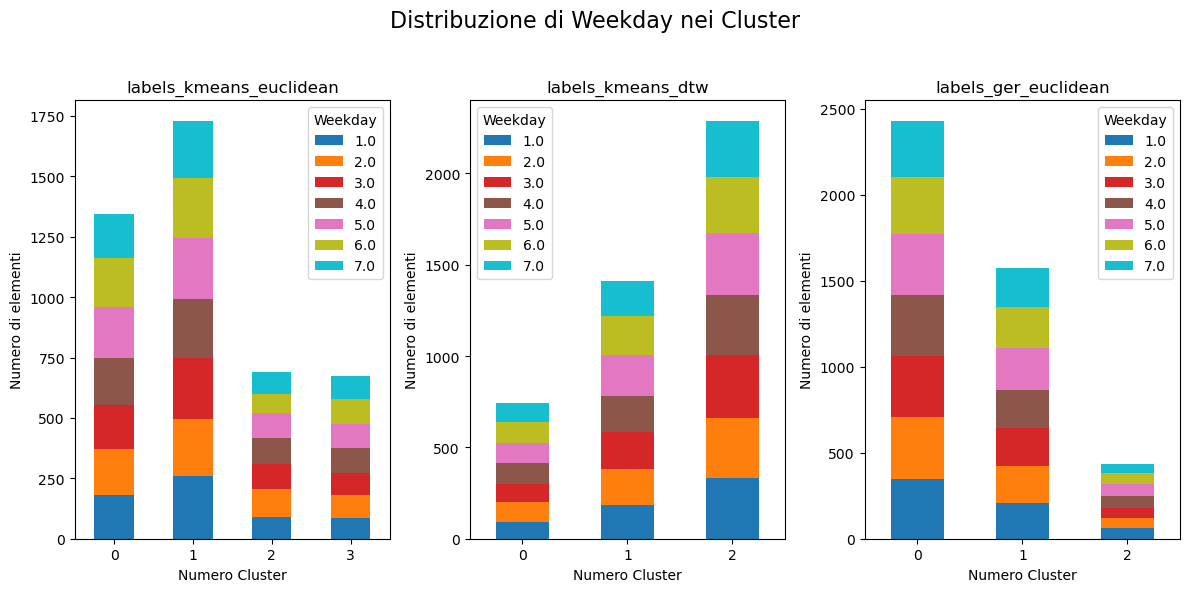

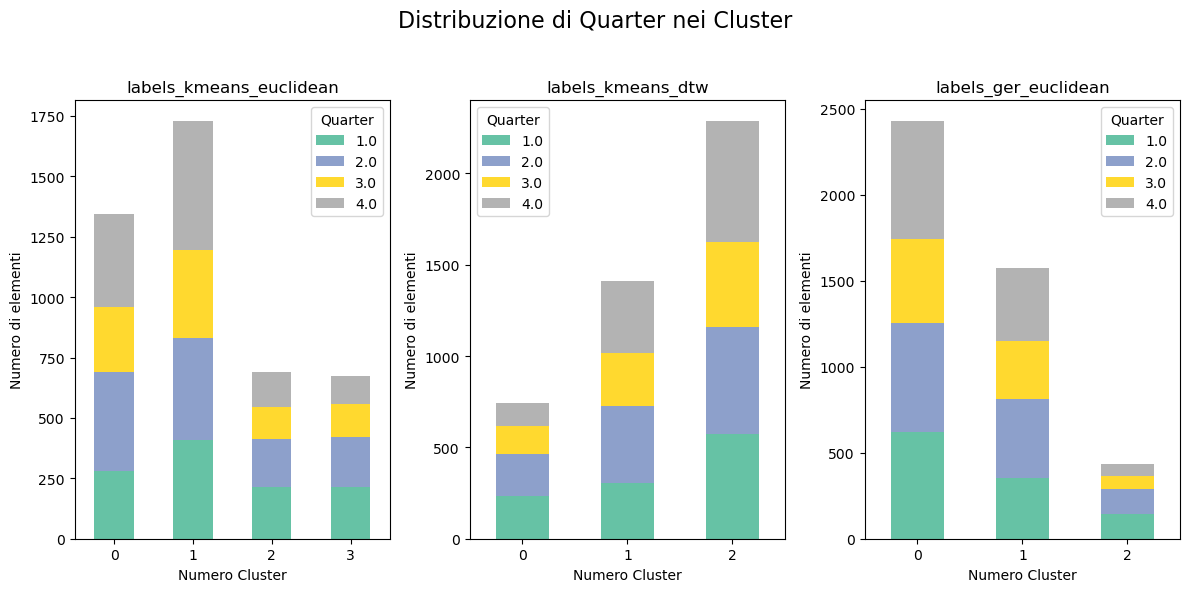

Medie di relative_date_PCIAT per ogni cluster e algoritmo:
            labels_kmeans_euclidean  labels_kmeans_dtw  labels_ger_euclidean
Cluster ID                                                                  
0                         52.495536          73.514785             49.681088
1                         49.072917          52.674716             54.439288
2                         51.681621          49.232385             80.430206
3                         74.618694                NaN                   NaN


In [22]:
# Istogrammi

# Sii
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
fig.suptitle("Distribuzione di Sii nei Cluster", fontsize=16)

for ax, (nome_tecnica, labels) in zip(axes, dict_labels.items()):
    df_plot = pd.DataFrame({
        'Cluster': labels,
        'Sii': sii_labels
    })
    crosstab = pd.crosstab(df_plot['Cluster'], df_plot['Sii'])

    crosstab.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['#1f77b4', '#ff7f0e']
    )
    ax.set_title(nome_tecnica)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Elementi")
    ax.legend(title='Sii')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Weekday
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
fig.suptitle("Distribuzione di Weekday nei Cluster", fontsize=16)
for ax, (nome_tecnica, labels) in zip(axes, dict_labels.items()):
    df_plot = pd.DataFrame({
        'Cluster': labels,
        'Weekday': weekday_labels
    })
    crosstab = pd.crosstab(df_plot['Cluster'], df_plot['Weekday'])

    crosstab.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        cmap='tab10'
    )
    ax.set_title(nome_tecnica)
    ax.set_xlabel("Numero Cluster")
    ax.set_ylabel("Numero di elementi")
    ax.legend(title='Weekday')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Quarter
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
fig.suptitle("Distribuzione di Quarter nei Cluster", fontsize=16)
for ax, (nome_tecnica, labels) in zip(axes, dict_labels.items()):
    df_plot = pd.DataFrame({
        'Cluster': labels,
        'Quarter': quarter_labels
    })
    crosstab = pd.crosstab(df_plot['Cluster'], df_plot['Quarter'])

    crosstab.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        cmap='Set2'
    )
    ax.set_title(nome_tecnica)
    ax.set_xlabel("Numero Cluster")
    ax.set_ylabel("Numero di elementi")
    ax.legend(title='Quarter')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Relative Date
dict_medie = {}

for nome_tecnica, labels_cluster in dict_labels.items():
    df_temp = pd.DataFrame({
        'Cluster': labels_cluster,
        'relative_date_PCIAT': relative_date_labels
    })

    media_per_cluster = df_temp.groupby(
        'Cluster')['relative_date_PCIAT'].mean()

    dict_medie[nome_tecnica] = media_per_cluster

df_medie = pd.DataFrame(dict_medie)
df_medie.index.name = 'Cluster ID'

print("Medie di relative_date_PCIAT per ogni cluster e algoritmo:")
print(df_medie)

## Validazione
---

Validazione Euclidea:   0%|          | 0/18 [00:00<?, ?it/s]

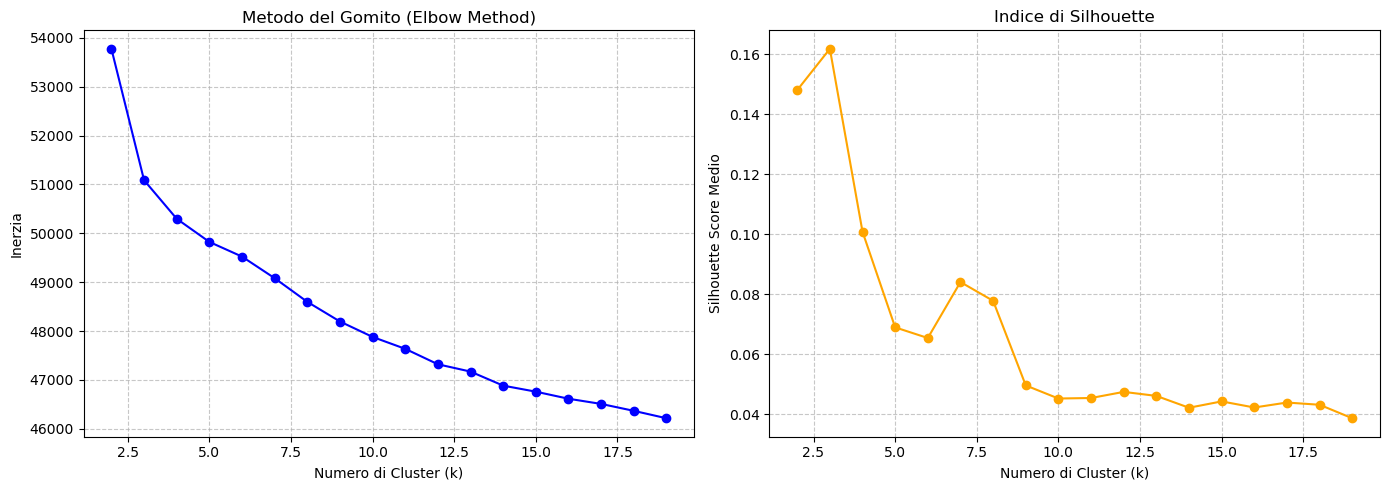

Validazione DTW:   0%|          | 0/8 [00:00<?, ?it/s]

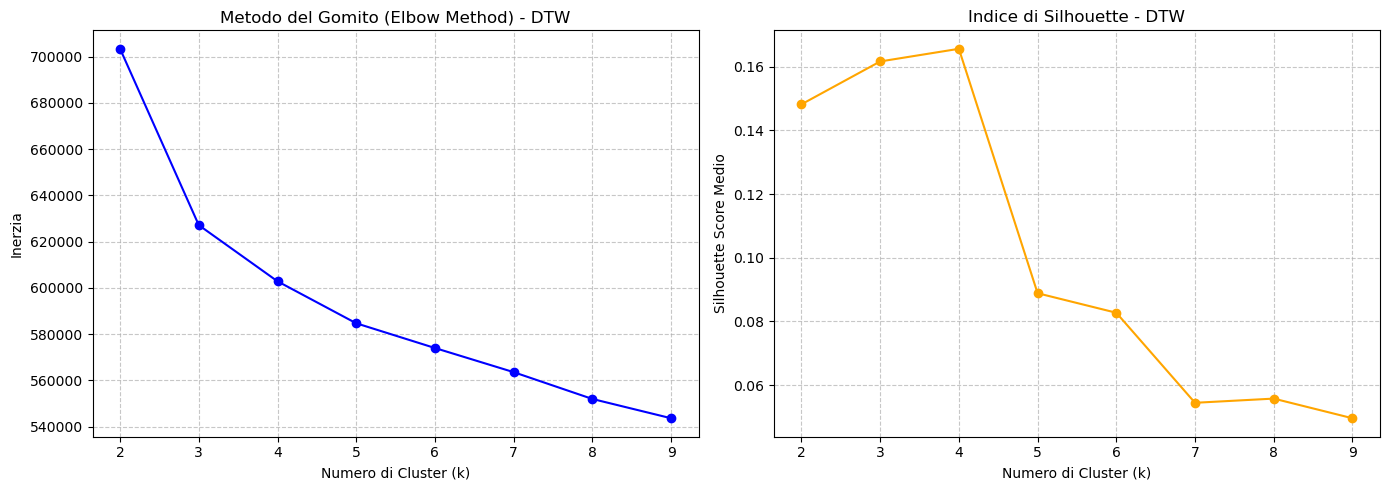

<Figure size 640x480 with 0 Axes>

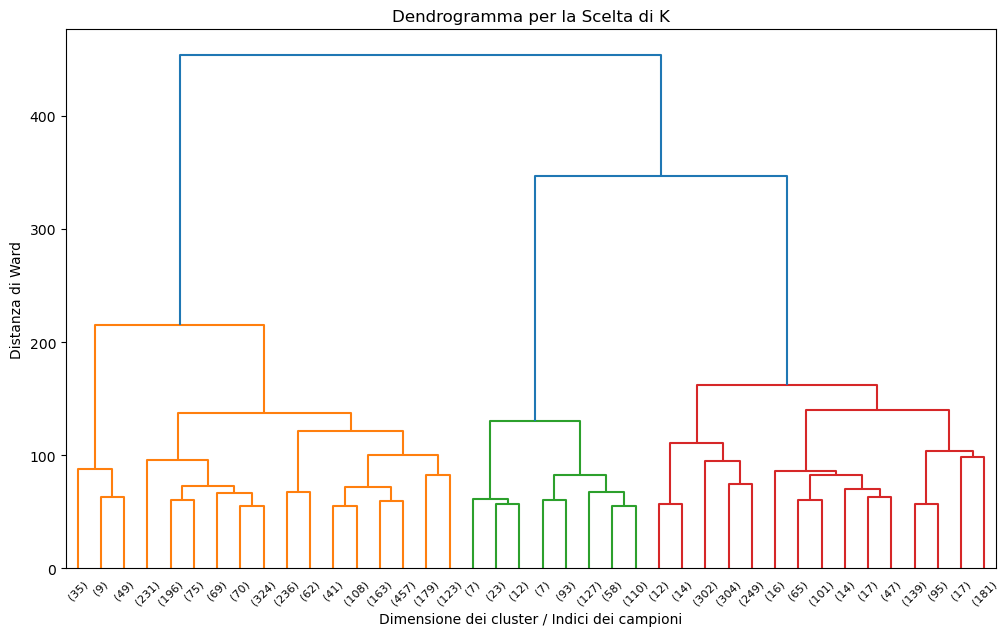

In [25]:
# ==========================================
# 1. Validazione per K-Means (Euclideo)
# ==========================================
k_range = range(2, 20)
inertia_values = []
silhouette_scores = []

for k_val in tqdm(k_range, desc="Validazione Euclidea"):
    kmeans_eval = TimeSeriesKMeans(
        n_clusters=k_val,
        metric="euclidean",
        random_state=222,
        init_algorithm="kmeans++",
        n_init=2
    )
    labels_eval = kmeans_eval.fit_predict(X_sktime)
    inertia_values.append(kmeans_eval.inertia_)
    score = silhouette_score(X_flattened, labels_eval, metric='euclidean')
    silhouette_scores.append(score)

# Visualizzazione Metodo del Gomito e Silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_range, inertia_values, marker='o', color='blue')
ax1.set_title('Metodo del Gomito (Elbow Method)')
ax1.set_xlabel('Numero di Cluster (k)')
ax1.set_ylabel('Inerzia')
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(k_range, silhouette_scores, marker='o', color='orange')
ax2.set_title('Indice di Silhouette')
ax2.set_xlabel('Numero di Cluster (k)')
ax2.set_ylabel('Silhouette Score Medio')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


# ==========================================
# 1.5 Validazione per K-Means (DTW)
# ==========================================
k_range_dtw = range(2, 10)
inertia_values_dtw = []
silhouette_scores_dtw = []

# Implementazione di tqdm per monitorare il ciclo
for k_val in tqdm(k_range_dtw, desc="Validazione DTW"):
    kmeans_eval = TimeSeriesKMeans(
        n_clusters=k_val,
        metric="dtw",
        random_state=222,
        init_algorithm="kmeans++",
        n_init=2,
        distance_params={"window": 0.1}
    )
    labels_eval = kmeans_eval.fit_predict(X_sktime)
    inertia_values_dtw.append(kmeans_eval.inertia_)
    score = silhouette_score(X_flattened, labels_eval, metric='euclidean')
    silhouette_scores_dtw.append(score)


# Visualizzazione Metodo del Gomito e Silhouette
# Visualizzazione Metodo del Gomito e Silhouette - DTW
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Sostituzione delle variabili con quelle del DTW
ax1.plot(k_range_dtw, inertia_values_dtw, marker='o', color='blue')
ax1.set_title('Metodo del Gomito (Elbow Method) - DTW')
ax1.set_xlabel('Numero di Cluster (k)')
ax1.set_ylabel('Inerzia')
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(k_range_dtw, silhouette_scores_dtw, marker='o', color='orange')
ax2.set_title('Indice di Silhouette - DTW')
ax2.set_xlabel('Numero di Cluster (k)')
ax2.set_ylabel('Silhouette Score Medio')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

plt.tight_layout()
plt.show()

# ==========================================
# 2. Validazione per Clustering Gerarchico
# ==========================================
# Il linkage 'ward' calcola le distanze in base alla varianza ed è coerente con l'implementazione
Z = linkage(X_flattened, method='ward')

plt.figure(figsize=(12, 7))
plt.title("Dendrogramma per la Scelta di K")
# Troncamento visivo per evitare un albero illeggibile in presenza di molti campioni
dendrogram(Z, truncate_mode='lastp', p=40)
plt.xlabel("Dimensione dei cluster / Indici dei campioni")
plt.ylabel("Distanza di Ward")
plt.show()

In [24]:
'''import numpy as np
import itertools
from sklearn.metrics import silhouette_score
from tqdm import tqdm
# Assumendo l'import di TimeSeriesKMeans da sktime

# 1. Definizione delle configurazioni di constraint per DTW
# A causa del bug di validazione interno di sktime sul parametro itakura_max_slope,
# lo spazio di ricerca viene limitato esclusivamente all'ottimizzazione del
# parametro 'window' (Sakoe-Chiba band).
dtw_configs = [
    {"window": 0.01},
    {"window": 0.05},
    {"window": 0.10},
    {"window": 0.15},
    {"window": 0.20}
]

# Definizione dello spazio di ricerca
param_grid = {
    'n_clusters': [2, 3, 4, 5, 6],
    'dtw_params': dtw_configs
}

best_silhouette = -1
best_params = {}
best_labels = None
best_model = None

# Generazione di tutte le combinazioni per l'iteratore unico
combinazioni = list(itertools.product(
    param_grid['n_clusters'], param_grid['dtw_params']))

# Applicazione di tqdm sul ciclo unificato
for n_clusters, dist_params in tqdm(combinazioni, desc="Grid Search K-Means DTW"):
    kmeans_dtw = TimeSeriesKMeans(
        n_clusters=n_clusters,
        metric="dtw",
        init_algorithm="kmeans++",
        n_init=1,
        random_state=222,
        distance_params=dist_params
    )

    # Esecuzione del modello
    labels = kmeans_dtw.fit_predict(X_sktime)

    # Valutazione tramite Coefficiente di Silhouette
    if len(np.unique(labels)) > 1:
        score = silhouette_score(X_flattened, labels, metric='euclidean')

        if score > best_silhouette:
            best_silhouette = score
            best_params = {'n_clusters': n_clusters,
                           'distance_params': dist_params}
            best_labels = labels
            best_model = kmeans_dtw

print("Migliori parametri trovati:", best_params)
print("Miglior Silhouette Score:", best_silhouette)
print("Numerosità cluster ottimale:", np.bincount(best_labels))'''

'import numpy as np\nimport itertools\nfrom sklearn.metrics import silhouette_score\nfrom tqdm import tqdm\n# Assumendo l\'import di TimeSeriesKMeans da sktime\n\n# 1. Definizione delle configurazioni di constraint per DTW\n# A causa del bug di validazione interno di sktime sul parametro itakura_max_slope,\n# lo spazio di ricerca viene limitato esclusivamente all\'ottimizzazione del\n# parametro \'window\' (Sakoe-Chiba band).\ndtw_configs = [\n    {"window": 0.01},\n    {"window": 0.05},\n    {"window": 0.10},\n    {"window": 0.15},\n    {"window": 0.20}\n]\n\n# Definizione dello spazio di ricerca\nparam_grid = {\n    \'n_clusters\': [2, 3, 4, 5, 6],\n    \'dtw_params\': dtw_configs\n}\n\nbest_silhouette = -1\nbest_params = {}\nbest_labels = None\nbest_model = None\n\n# Generazione di tutte le combinazioni per l\'iteratore unico\ncombinazioni = list(itertools.product(\n    param_grid[\'n_clusters\'], param_grid[\'dtw_params\']))\n\n# Applicazione di tqdm sul ciclo unificato\nfor n_clus